<a href="https://colab.research.google.com/github/TamalSana/ECS/blob/main/YOLO_PICO_Baseline_vs_Modified_%5BAnalyse_Public_Sport_Infra%5D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **<font color="#0000FB" size="20"><b>YOLO-PICO</b></font>**

## **<font color="black" size="5"><b>Clone YOLO-PICO repo</b></font>**

In [ ]:
!git clone https://github.com/MohamadEbrahimAghili/YOLO-PICO.git

Cloning into 'YOLO-PICO'...
remote: Enumerating objects: 42, done.
remote: Counting objects: 100% (23/23), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 42 (delta 12), reused 3 (delta 3), pack-reused 19 (from 1)
Receiving objects: 100% (42/42), 73.26 MiB | 43.69 MiB/s, done.
Resolving deltas: 100% (13/13), done.


# **<font color="black" size="6"><b>SETUP: DATASET</b></font>**

## **<font color="black" size="5"><b>Unzip dataset</b></font>**

In [ ]:
!7z x /content/YOLO-PICO/NWPU-VHR-10.zip -o/content/


7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576

Scanning the drive for archives:
  0M Scan /content/YOLO-PICO/                             1 file, 24553153 bytes (24 MiB)

Extracting archive: /content/YOLO-PICO/NWPU-VHR-10.zip
--
Path = /content/YOLO-PICO/NWPU-VHR-10.zip
Type = zip
Physical Size = 24553153
Embedded Stub Size = 4
Total Physical Size = 76981953
Multivolume = +
Volume Index = 2
Volumes = 3

  0%     28% 873         60% 1138          93% 1561         Everything is Ok

Folders: 11
Files: 1601
Size:       76926587
Compressed: 76981953


## **<font color="black" size="5"><b>Create Custom Sports Dataset Copy (Isolated Config)</b></font>**
To keep the original dataset unmodified, we copy the images and process only the labels in a separate target directory: `/content/NWPU-VHR-10-sports`.

In [ ]:
import shutil
import os

source_dir = '/content/NWPU-VHR-10'
target_dir = '/content/NWPU-VHR-10-sports'

# Create a fresh copy of the dataset to work on
if os.path.exists(target_dir):
    shutil.rmtree(target_dir)

shutil.copytree(source_dir, target_dir)
print(f"Copied dataset to {target_dir} for isolated sports configuration!")

Copied dataset to /content/NWPU-VHR-10-sports for isolated sports configuration!


In [ ]:
class_map = {
    2: 0,  # basketball court -> 0
    4: 1,  # ground track field -> 1
    8: 2   # tennis court -> 2
}

label_dirs = [
    '/content/NWPU-VHR-10-sports/train/labels',
    '/content/NWPU-VHR-10-sports/valid/labels',
    '/content/NWPU-VHR-10-sports/test/labels'
]

# Filter labels in our isolated directory copy
for label_dir in label_dirs:
    if not os.path.exists(label_dir):
        print(f"Directory {label_dir} not found. Skipping...")
        continue

    txt_files = [f for f in os.listdir(label_dir) if f.endswith('.txt')]
    for txt_file in txt_files:
        file_path = os.path.join(label_dir, txt_file)

        with open(file_path, 'r') as f:
            lines = f.readlines()

        new_lines = []
        for line in lines:
            parts = line.strip().split()
            if not parts:
                continue
            class_id = int(parts[0])

            if class_id in class_map:
                new_class_id = class_map[class_id]
                parts[0] = str(new_class_id)
                new_lines.append(" ".join(parts) + "\n")

        with open(file_path, 'w') as f:
            f.writelines(new_lines)

print("Sports labels filtered successfully in isolated directory.")

Sports labels filtered successfully in isolated directory.


In [ ]:
new_yaml_content = """names:
- basketball court
- ground track field
- tennis court
nc: 3
test: ../test/images
train: ../train/images
val: ../valid/images
"""

with open('/content/NWPU-VHR-10-sports/data.yaml', 'w') as f:
    f.write(new_yaml_content)

print("New isolated data.yaml configured!")

New isolated data.yaml configured!


## **<font color="black" size="5"><b>Install ultralytics</b></font>**

In [ ]:
!pip install -q ultralytics==8.4.60

#**<font color="black" size="6"><b>SETUP: MODEL</b></font>**

## **<font color="black" size="5"><b>Add YOLO-PICO Expansion Attention Module</b></font>**

In [ ]:
location = !pip show ultralytics | awk -F": " '/Location/ {print $2}'
ULTRALYTICS_PATH = location[0] + "/ultralytics"
print(ULTRALYTICS_PATH)

/usr/local/lib/python3.13/dist-packages/ultralytics


In [ ]:
!cp -f /content/YOLO-PICO/__init__.py $ULTRALYTICS_PATH/nn/modules/
!cp -f /content/YOLO-PICO/block.py $ULTRALYTICS_PATH/nn/modules/
!cp -f /content/YOLO-PICO/tasks.py $ULTRALYTICS_PATH/nn/

## **<font color="black" size="5"><b>Read YOLO-PICO model</b></font>**

In [ ]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
model = YOLO("/content/YOLO-PICO/YOLO_PICO.yaml")

## **<font color="black" size="5"><b>Model Modification</b></font>**

In [ ]:
import re

# Let's read the baseline YOLO-PICO configuration file
with open('/content/YOLO-PICO/YOLO_PICO.yaml', 'r') as f:
    yaml_content = f.read()

# A simple beginner-friendly modification:
# We will replace the default activation functions or adjust the width scaling to see the effect on performance.
# For example, let's create a variant that uses LeakyReLU activations instead of SiLU (or adjusts the depth/width channel multiplier).
# In Ultralytics YAML configs, we can modify the scaling factor 'width' or 'depth' to scale the network capacity.
# Let's slightly increase the width factor from 0.25 to 0.35 to increase network capacity (wider layers).
modified_yaml = yaml_content.replace('width: 0.25', 'width: 0.35')

with open('/content/YOLO_PICO_modified.yaml', 'w') as f:
    f.write(modified_yaml)

print("Created modified architecture config: /content/YOLO_PICO_modified.yaml (Increased channel width from 0.25 to 0.35)")

Created modified architecture config: /content/YOLO_PICO_modified.yaml (Increased channel width from 0.25 to 0.35)


# **<font color="black" size="6"><b>SETUP: TRAINING & VALIDATION</b></font>**

## **<font color="black" size="5"><b>Training Configuration</b></font>**

In [ ]:
config = {
    'optimizer': 'SGD',
    'imgsz': 1024, # input RF
    'nms': True, # Non-Maximum Suppression (NMS)
    'workers': 8,
    'patience': 100,
    'lr0': 0.01,
    'lrf': 0.01,
# I trained YOLO-PICO from scratch (400 epochs)
# but you can use COCO pretrained weights (20 epochs for weak train and test)
    'pretrained': True,
    'verbose': True,
    'seed': 42,
    'close_mosaic': 0,
    'momentum': 0.937,
    'weight_decay': 0.005, # L2 regularization (increased from 0.001 to prevent overfitting)
    'warmup_epochs': 3,
    'warmup_momentum': 0.8,
    'warmup_bias_lr': 0.1,
    'box': 7.5, # Weight of the box loss component
    'cls': 0.5, # Weight of the classification loss
    'dfl': 1.5, # Weight of the distribution focal loss
    'dropout': 0.15, # Dropout rate (increased from 0.10 to prevent overfitting)
    'plots': True,
    'augment': False,
    'hsv_h': 0.015,
    'hsv_s': 0.7,
    'hsv_v': 0.4,
    'degrees': 180,
    'translate': 0.1,
    'scale': 0.3,
    'shear': 0.0,
    'perspective': 0.0,
    'flipud': 0.3,
    'fliplr':0.3,
    'bgr': 0.0,
    'mosaic': 0.2,
    'mixup': 0.3,
    'copy_paste': 0.2,
    'erasing': 0.4,
    'crop_fraction': 0.0
}

## **<font color="black" size="5"><b>Check GPU</b></font>**

In [ ]:
import torch

if torch.cuda.is_available():
    DEVICE = [0]  # Use GPU
    print(f"GPU detected: {torch.cuda.get_device_name(0)}. Using GPU.")
else:
    DEVICE = 'cpu'  # Fall back to CPU
    print("No GPU detected. Using CPU.")

GPU detected: Tesla T4. Using GPU.


## **<font color="black" size="5"><b>Train YOLO-PICO: BASE</b></font>**

In [ ]:
from ultralytics import YOLO
import os

# Load YOLO-PICO architecture and transfer pretrained weights from yolov8n.pt
model_pretrained = YOLO('/content/YOLO-PICO/YOLO_PICO.yaml').load('yolov8n.pt')

# Run the 20 epochs weak training pointing to our newly isolated sports dataset config
train_results_pretrained = model_pretrained.train(
    data=os.path.abspath("/content/NWPU-VHR-10-sports/data.yaml"),
    **config,
    batch=-1,
    epochs=20,
    device=DEVICE
)

Transferred 14/215 items from pretrained weights
New https://pypi.org/project/ultralytics/8.4.211 available 😃 Update with 'pip install -U ultralytics'
WARNING ⚠️ 'crop_fraction' is deprecated and will be removed in the future.
Ultralytics 8.4.60 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.2, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/NWPU-VHR-10-sports/data.yaml, degrees=180, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.1, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.3, flipud=0.3, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01

## Train YOLO_PICO: MOD
Now we can instantiate this modified model structure and train it using the same 3-class sports dataset configuration so we can compare the results directly to the baseline.

In [ ]:
# Initialize the modified model from the new YAML config
model_modified = YOLO('/content/YOLO_PICO_modified.yaml').load('yolov8n.pt')

# Train using the exact same sports dataset and configuration settings
train_results_modified = model_modified.train(
    data="/content/NWPU-VHR-10-sports/data.yaml",
    **config,
    batch=-1,
    epochs=20,
    device=DEVICE,
    name='train_modified'  # Saves to /content/runs/detect/train_modified
)

Transferred 14/215 items from pretrained weights
New https://pypi.org/project/ultralytics/8.4.211 available 😃 Update with 'pip install -U ultralytics'
WARNING ⚠️ 'crop_fraction' is deprecated and will be removed in the future.
Ultralytics 8.4.60 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.2, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/NWPU-VHR-10-sports/data.yaml, degrees=180, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.1, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.3, flipud=0.3, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01

## **<font color="black" size="5"><b>Test YOLO-PICO: BASE</b></font>**

In [ ]:
# Load the best weights from our training run and run the evaluation on the test split
best_model = YOLO('/content/runs/detect/train/weights/best.pt')
test_results = best_model.val(data="/content/NWPU-VHR-10-sports/data.yaml", split="test")

Ultralytics 8.4.60 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO_PICO summary (fused): 69 layers, 786,606 parameters, 0 gradients, 3.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2390.1±546.0 MB/s, size: 118.2 KB)
val: Scanning /content/NWPU-VHR-10-sports/test/labels.cache... 80 images, 59 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 80/80 17.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.5it/s 3.3s
                   all         80         65      0.885      0.208      0.245     0.0634
      basketball court         10         24          1          0     0.0725     0.0193
    ground track field          8          8      0.655      0.625       0.58      0.136
          tennis court          8         33          1          0     0.0837      0.035
Speed: 14.4ms preprocess, 6.9ms inference, 0.0ms loss, 3.5ms postprocess per image
Results saved to /content/runs/detect/val


## **<font color="black" size="5"><b>Test YOLO-PICO: MOD</b></font>**


In [ ]:
# Load the best weights from the modified training run and run evaluation on the test split
best_modified_model = YOLO('/content/runs/detect/train_modified/weights/best.pt')
test_results_modified = best_modified_model.val(data="/content/NWPU-VHR-10-sports/data.yaml", split="test", name='val_modified')


Ultralytics 8.4.60 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO_PICO_modified summary (fused): 69 layers, 786,606 parameters, 0 gradients, 3.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 32.3±23.4 MB/s, size: 83.9 KB)
val: Scanning /content/NWPU-VHR-10-sports/test/labels... 80 images, 59 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 80/80 561.0it/s 0.1s
val: New cache created: /content/NWPU-VHR-10-sports/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.1it/s 4.5s
                   all         80         65      0.723      0.248      0.233     0.0634
      basketball court         10         24          1          0     0.0396    0.00793
    ground track field          8          8      0.624      0.623      0.508      0.127
          tennis court          8         33      0.544      0.121      0.152     0.0552
Speed: 16.5ms preprocess, 6.7ms inference, 0.0ms loss, 5.8ms

# **<font color="black" size="5"><b>RESULT VISUALISATION</b></font>**

<font color="red" size="5"><b>You can see train and validation results in "/content/runs/detect/train"</b></font>

<font color="red" size="5"><b>for test results, see: "/content/runs/detect/val"</b></font>

In [ ]:
import os
import base64
from IPython.display import HTML, display

def display_mosaic(folder_path):
    if not os.path.exists(folder_path):
        print(f"Error: The path '{folder_path}' does not exist.")
        return

    image_files = [f for f in os.listdir(folder_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    image_files.sort()

    if not image_files:
        print(f"No .png, .jpg, or .jpeg images found in '{folder_path}'.")
        return

    html_code = """
    <style>
      /* The Mosaic Grid */
      .gallery {
        display: grid;
        grid-template-columns: repeat(auto-fill, minmax(200px, 1fr));
        gap: 15px;
        padding: 10px;
      }
      .gallery img {
        width: 100%;
        height: 200px;
        object-fit: contain; /* Keeps aspect ratio inside the thumbnail */
        background-color: #f0f0f0;
        cursor: pointer;
        border: 1px solid #ddd;
        border-radius: 4px;
        transition: transform 0.2s;
      }
      .gallery img:hover {
        transform: scale(1.05);
        box-shadow: 0 4px 8px rgba(0,0,0,0.2);
      }
      .filename {
        text-align: center;
        font-size: 12px;
        font-family: monospace;
        margin-top: 5px;
        word-wrap: break-word;
      }

      /* The Pop-up Modal (Lightbox) */
      #imgModal {
        display: none;
        position: fixed;
        z-index: 9999;
        left: 0;
        top: 0;
        width: 100%;
        height: 100%;
        background-color: rgba(0,0,0,0.9);
      }
      #modalImg {
        margin: auto;
        display: block;
        max-width: 95%;
        max-height: 90%;
        margin-top: 2%;
      }
      #caption {
        margin: auto;
        display: block;
        width: 80%;
        text-align: center;
        color: white;
        padding: 10px 0;
        font-family: monospace;
        font-size: 16px;
      }
    </style>

    <div class="gallery">
    """

    for img_name in image_files:
        img_path = os.path.join(folder_path, img_name)
        try:
            with open(img_path, "rb") as f:
                data = base64.b64encode(f.read()).decode('utf-8')
                ext = img_name.split('.')[-1]
                b64_string = f"data:image/{ext};base64,{data}"

                html_code += f'''
                <div>
                    <img src="{b64_string}" alt="{img_name}" onclick="openModal(this)">
                    <div class="filename">{img_name}</div>
                </div>
                '''
        except Exception as e:
            continue

    html_code += """
    </div>

    <!-- Modal Element -->
    <div id="imgModal" onclick="closeModal()">
      <img id="modalImg">
      <div id="caption"></div>
    </div>

    <script>
      function openModal(element) {
        document.getElementById("imgModal").style.display = "block";
        document.getElementById("modalImg").src = element.src;
        document.getElementById("caption").innerHTML = element.alt + " (Click anywhere to close)";
      }
      function closeModal() {
        document.getElementById("imgModal").style.display = "none";
      }
    </script>
    """

    display(HTML(html_code))

## **<font color="black" size="5"><b>Visualize: Train</b></font>**
**<font color="orange" size="5"><b>You can click each image to open. (click anywhere to close)</b></font>**



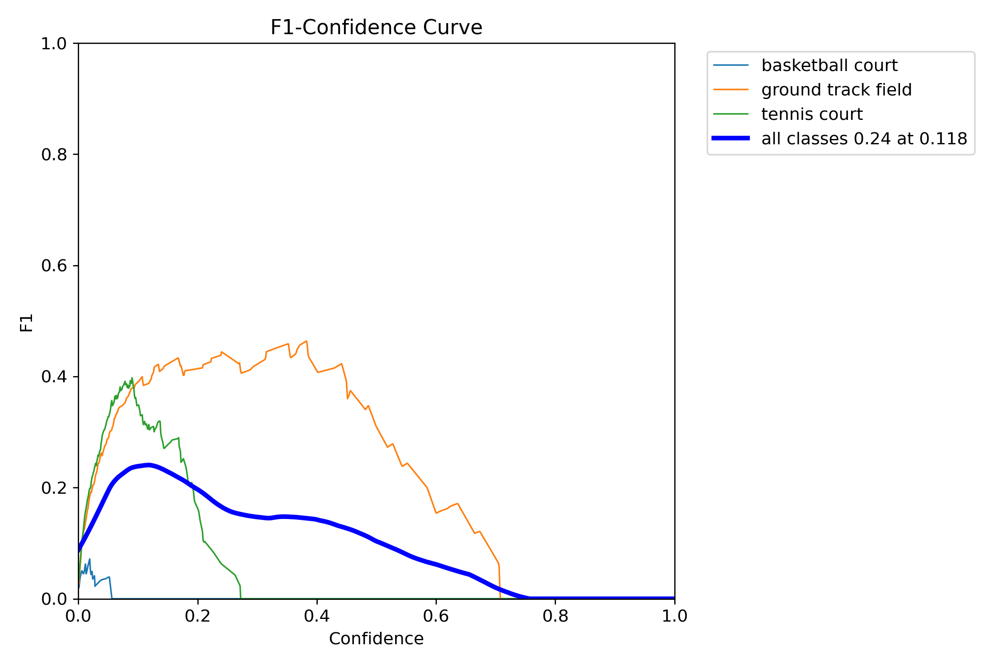
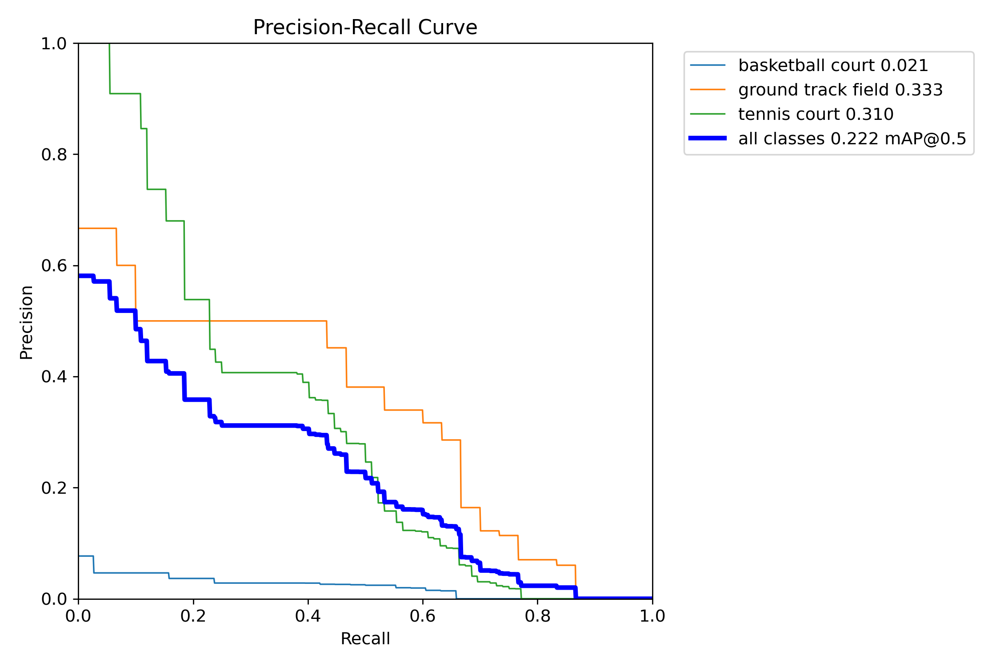
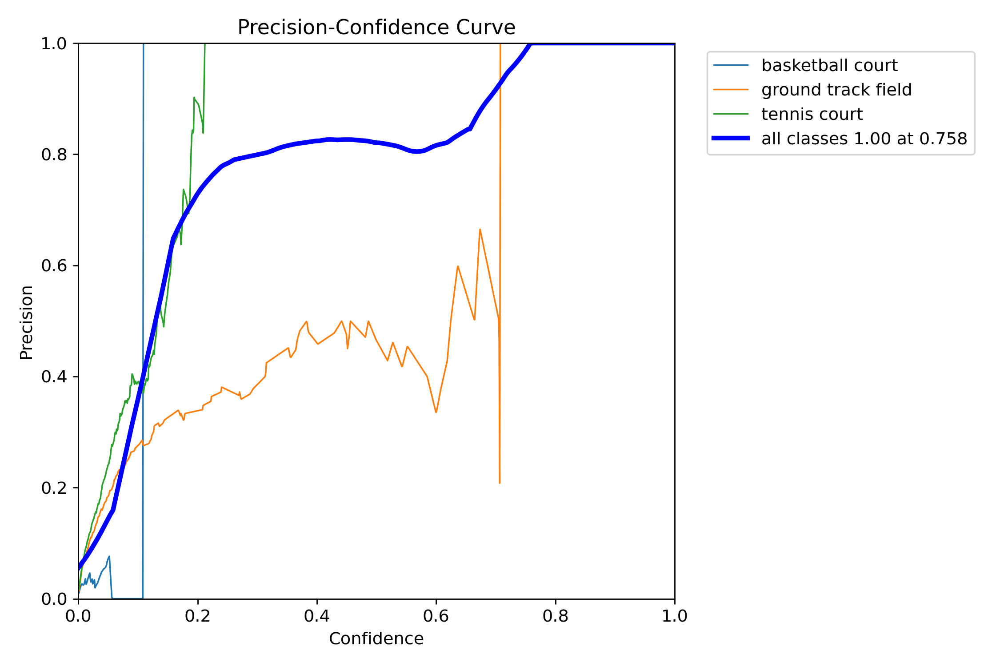
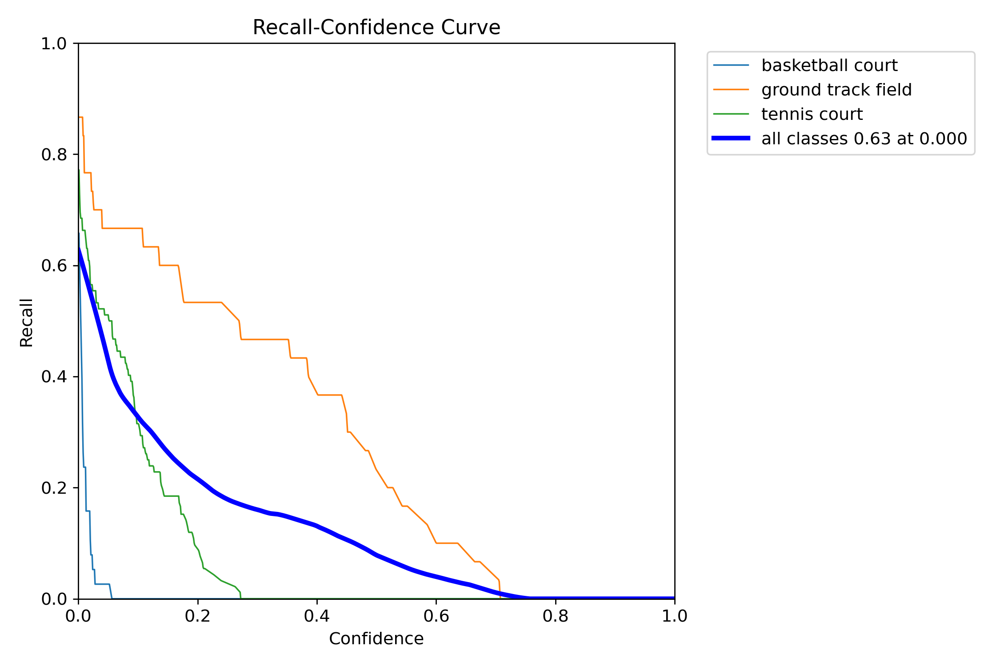
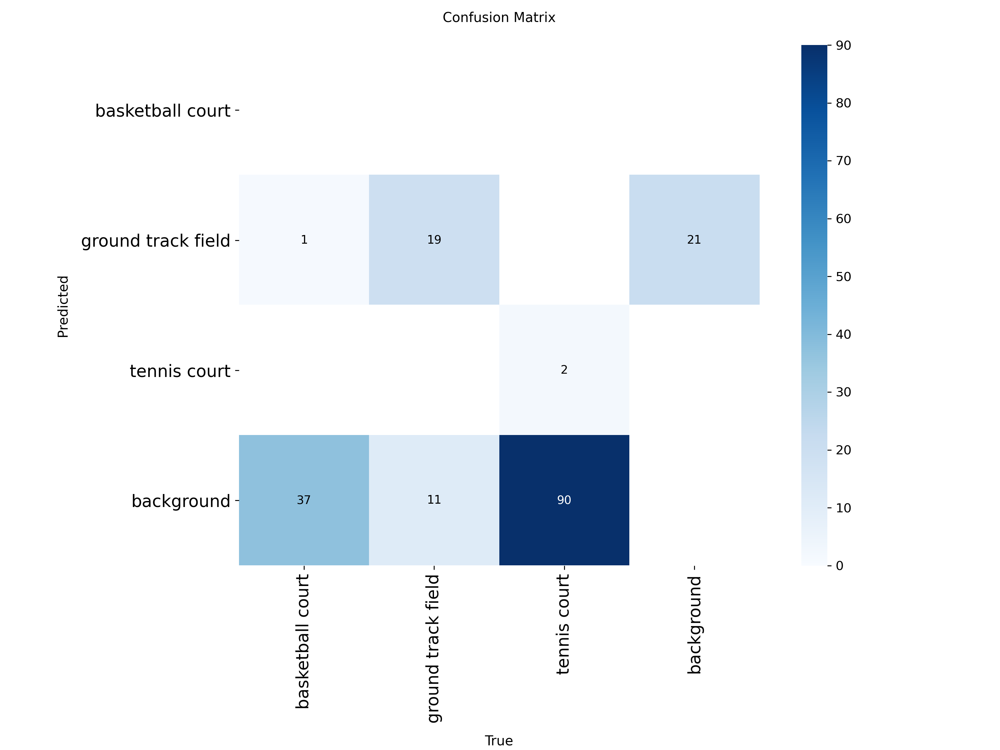
...
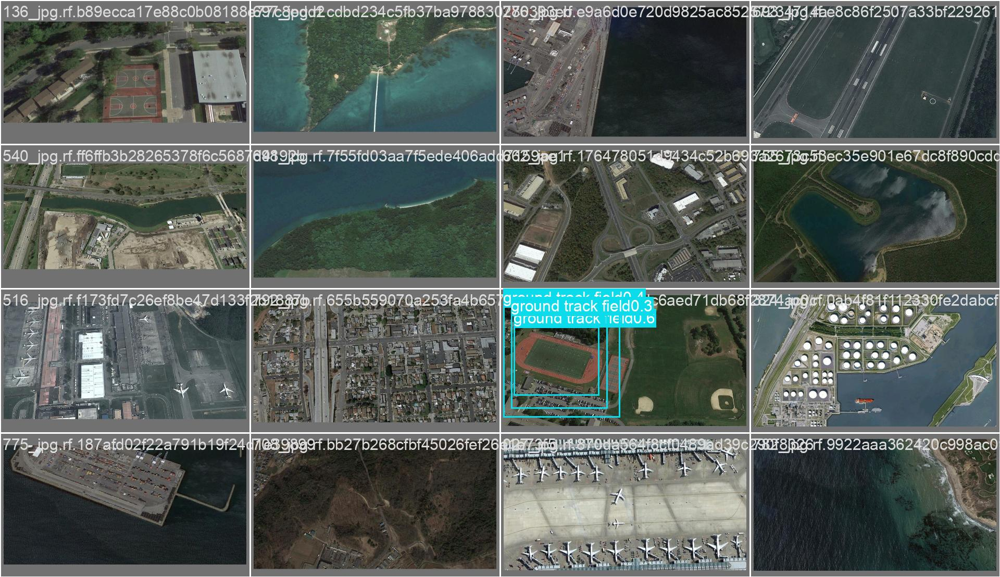
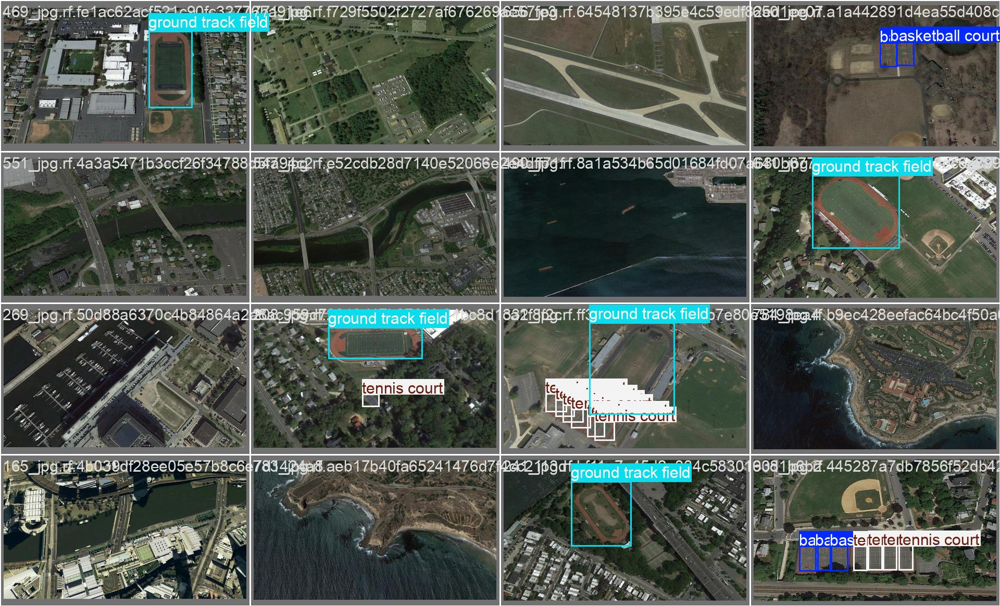
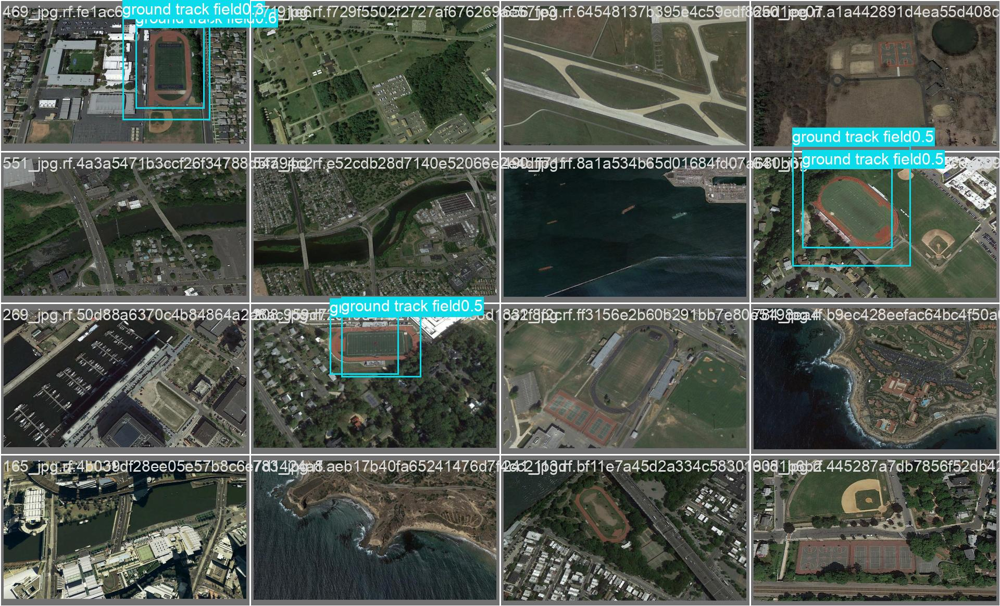
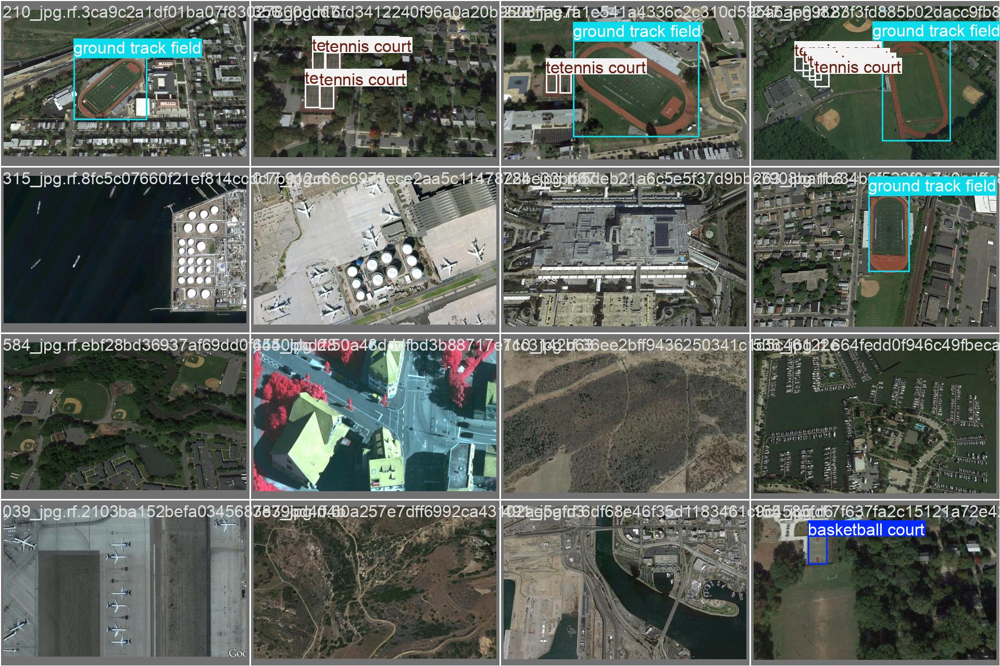
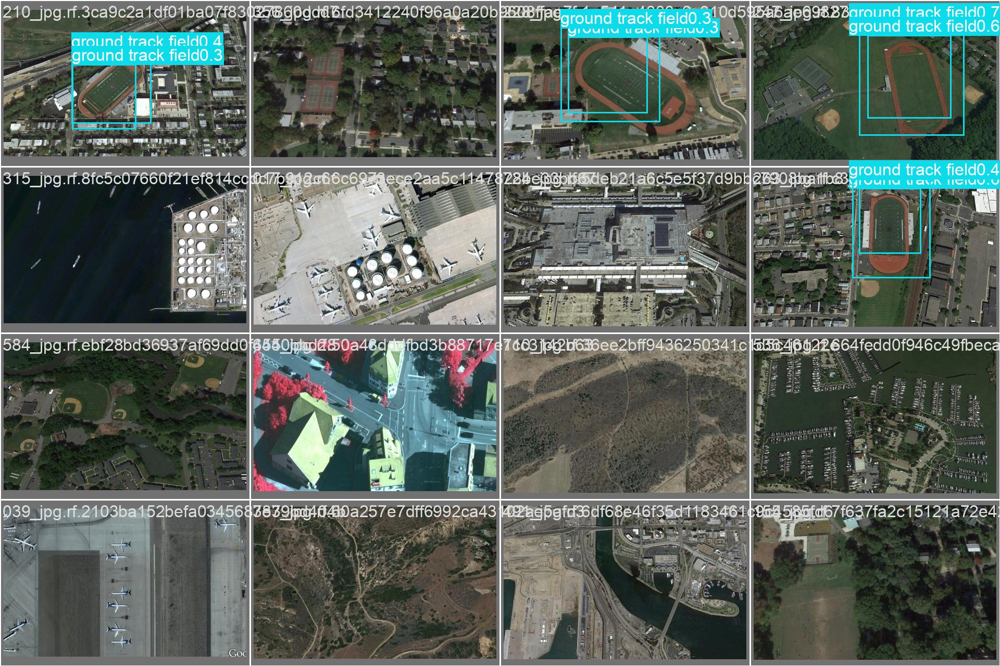

In [ ]:
display_mosaic('/content/runs/detect/train')


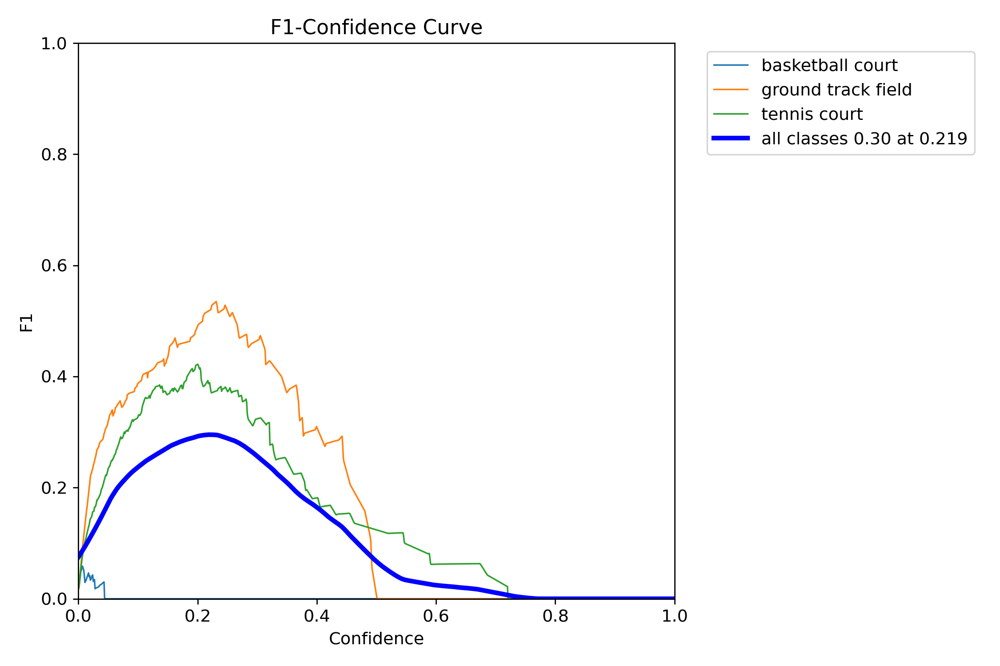
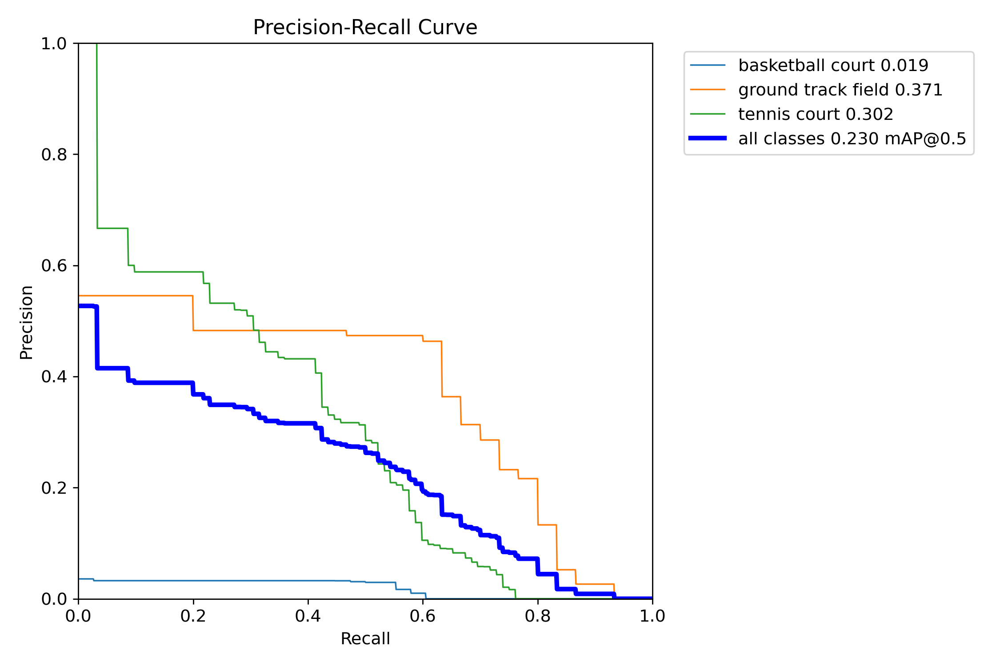
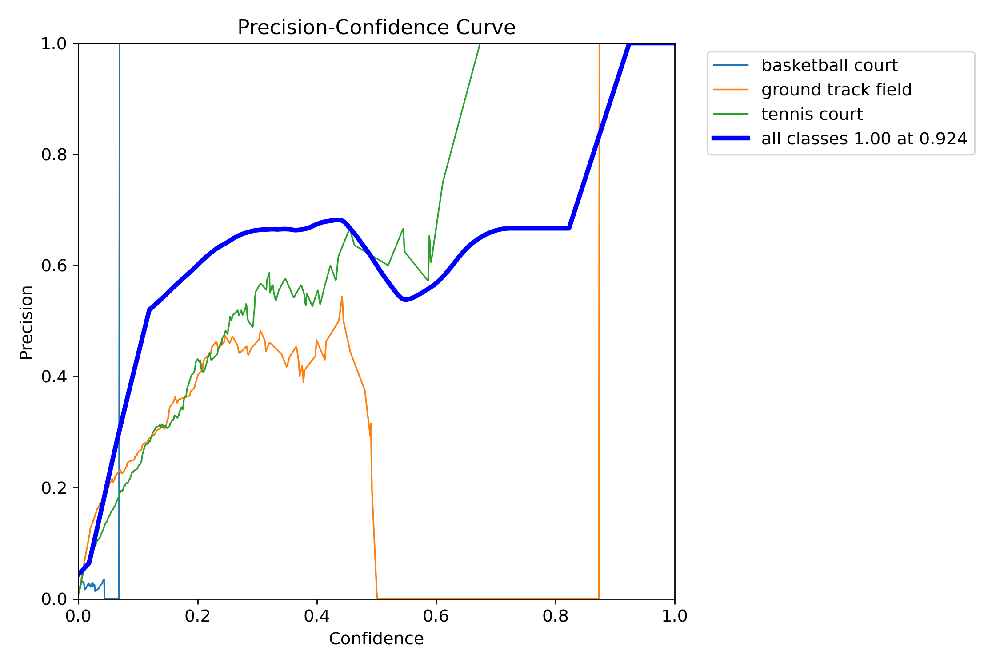
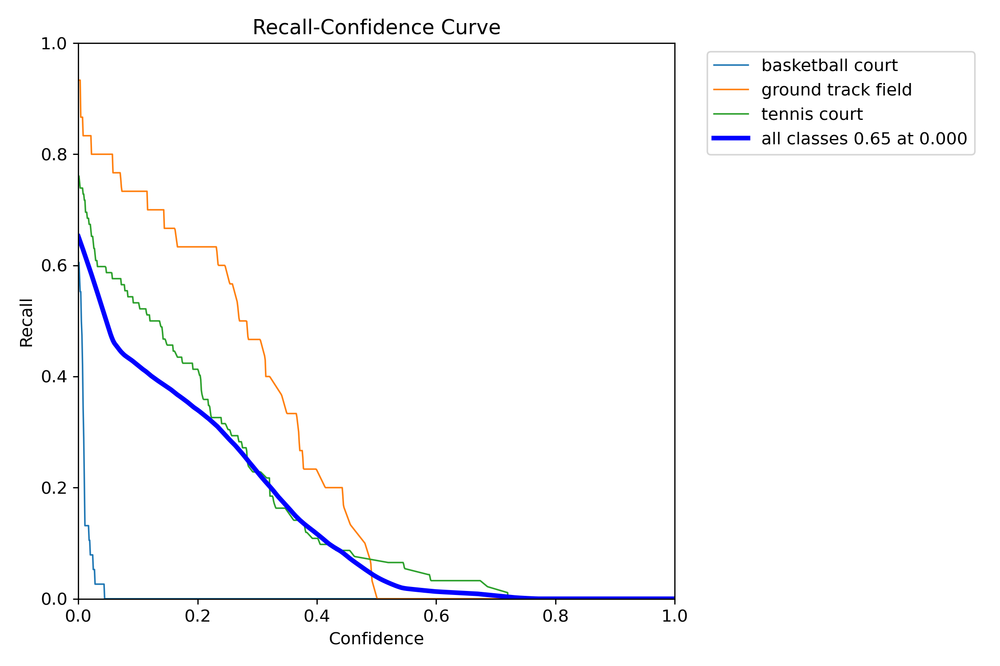
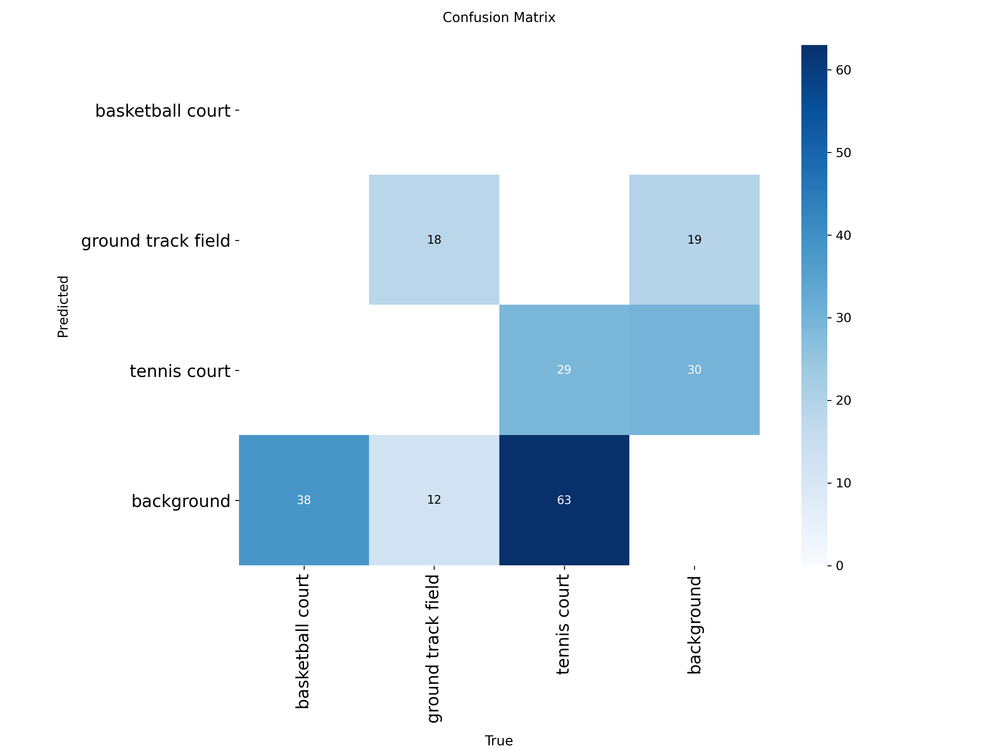
...
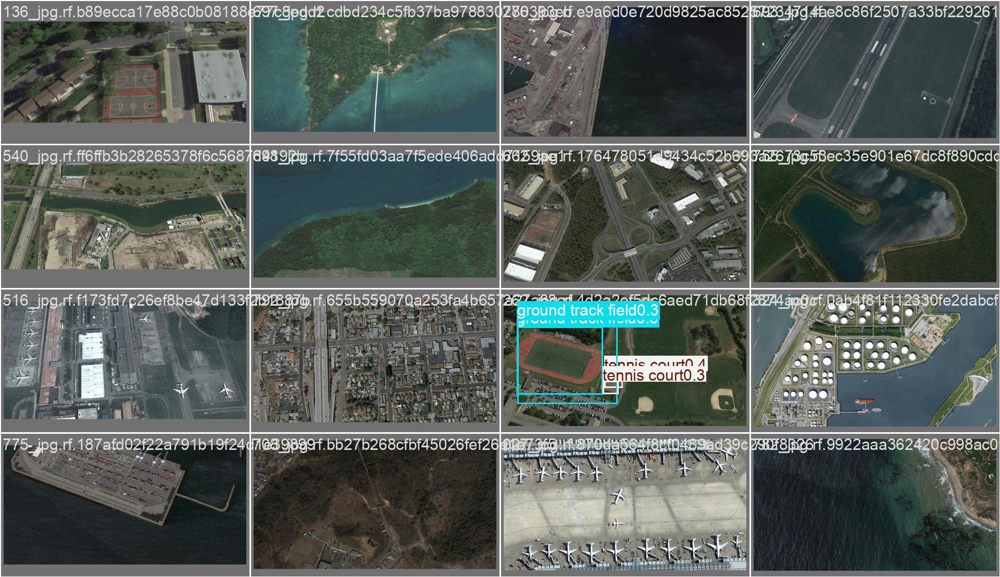
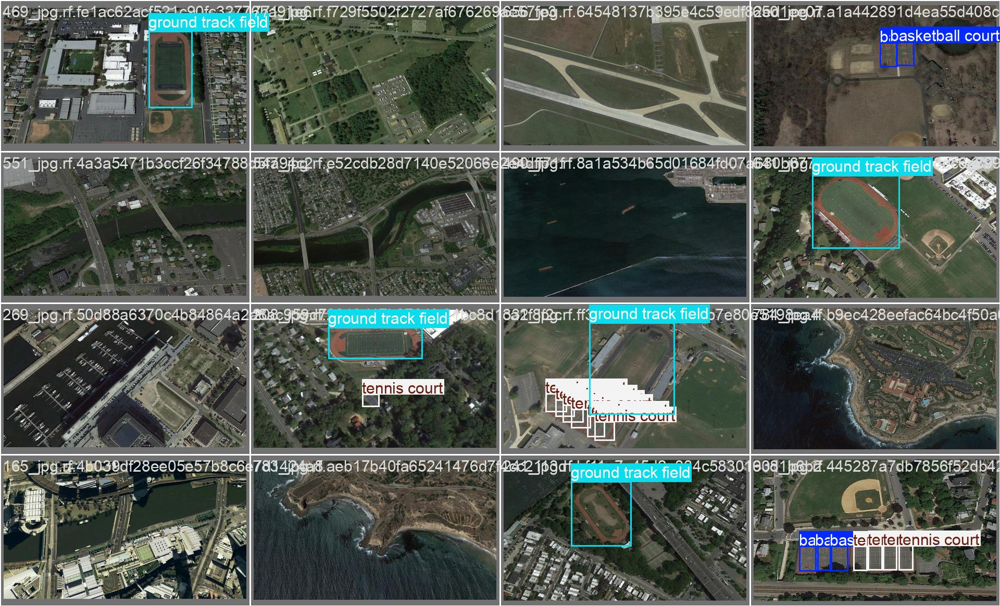
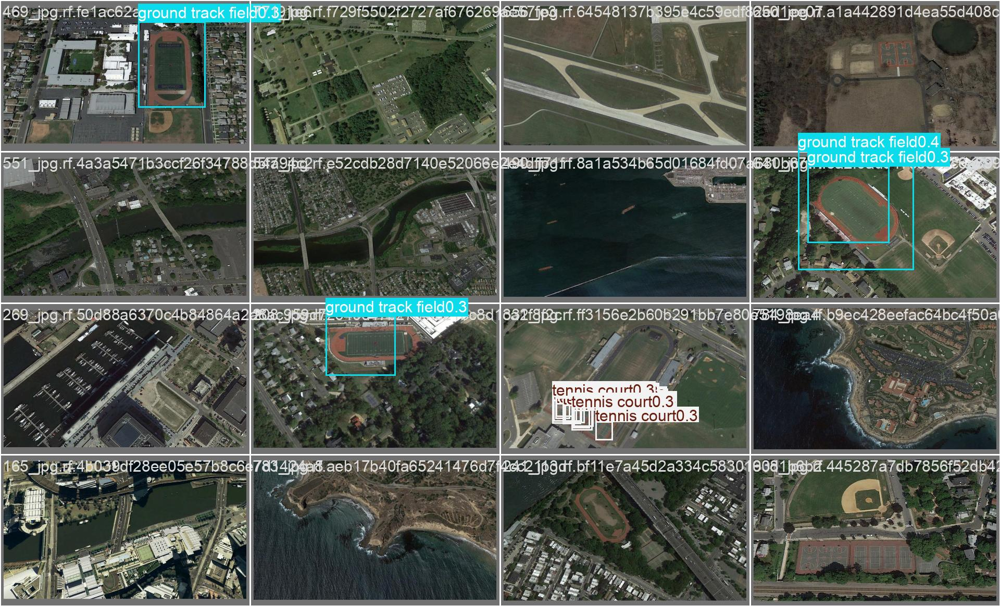
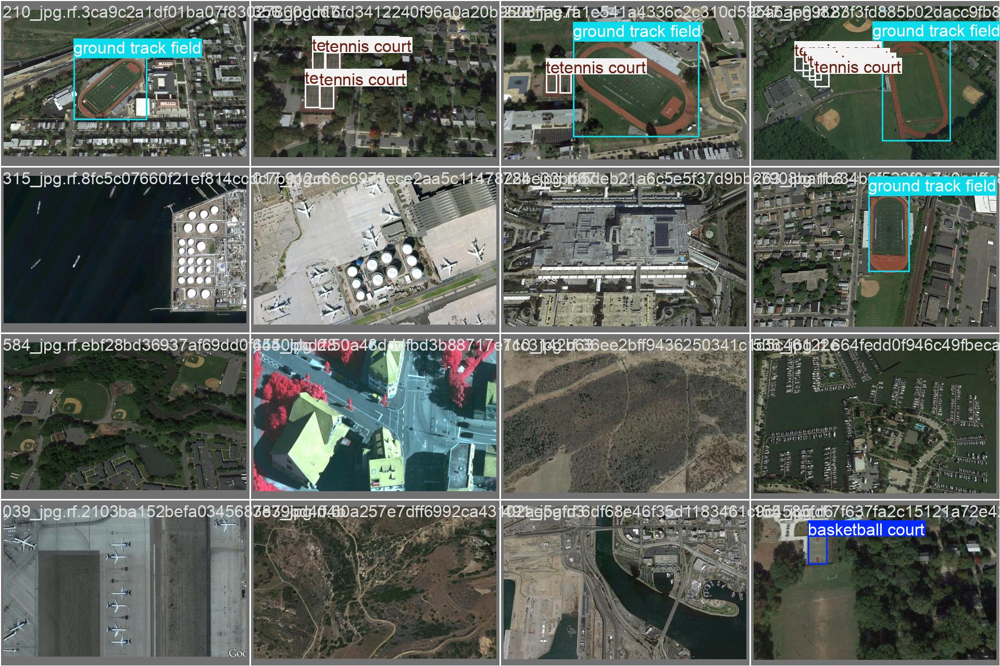
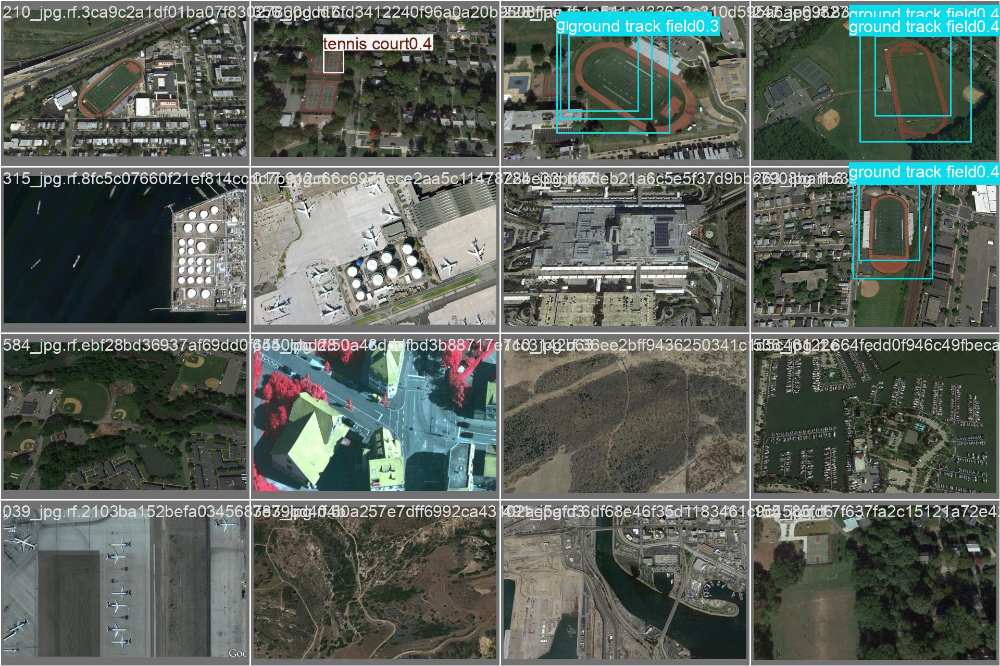

In [ ]:
# Display the training results and performance curves for the modified model
display_mosaic('/content/runs/detect/train_modified')

## **<font color="black" size="5"><b>Visualize: Validation</b></font>**
**<font color="orange" size="5"><b>You can click each image to open. (click anywhere to close)</b></font>**



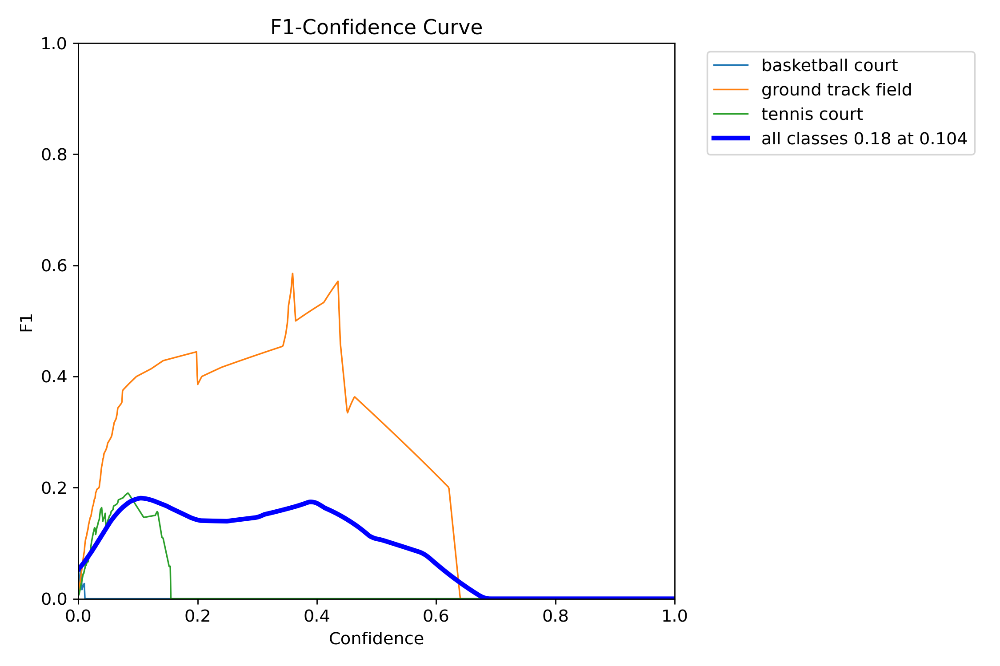
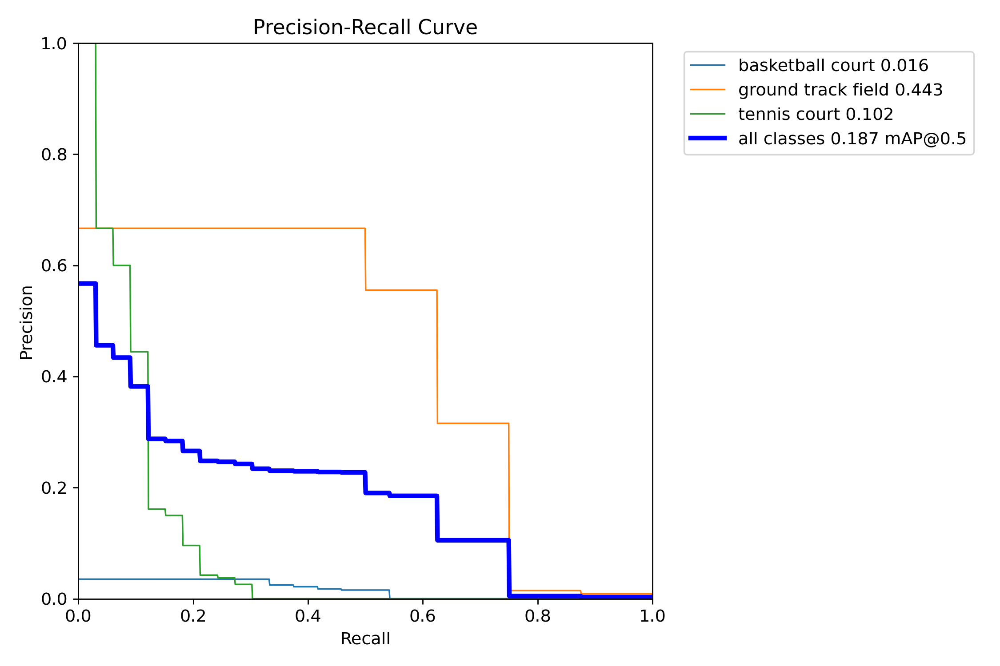
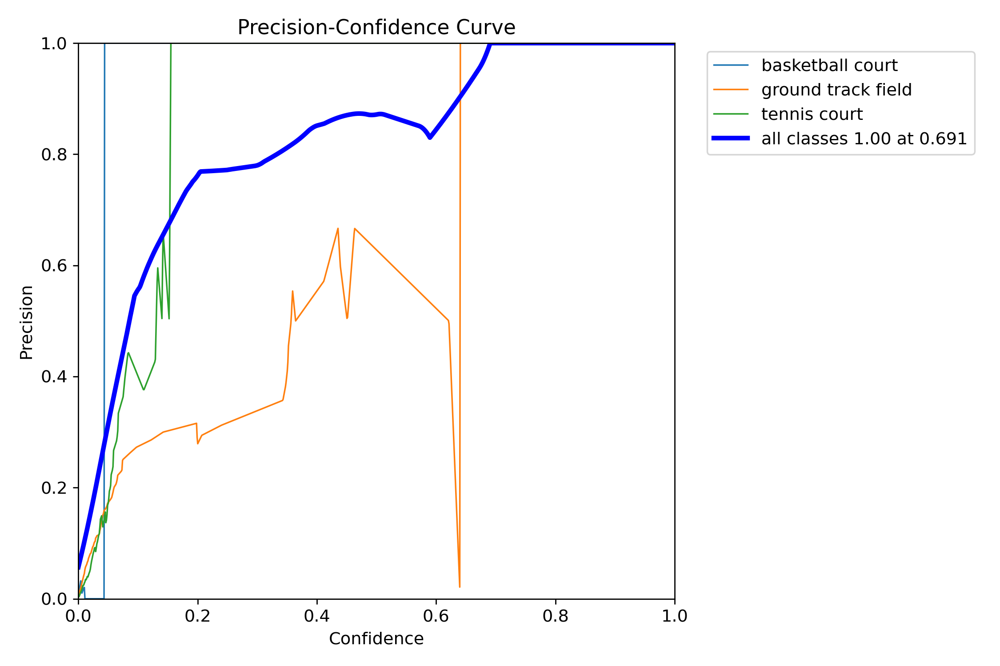
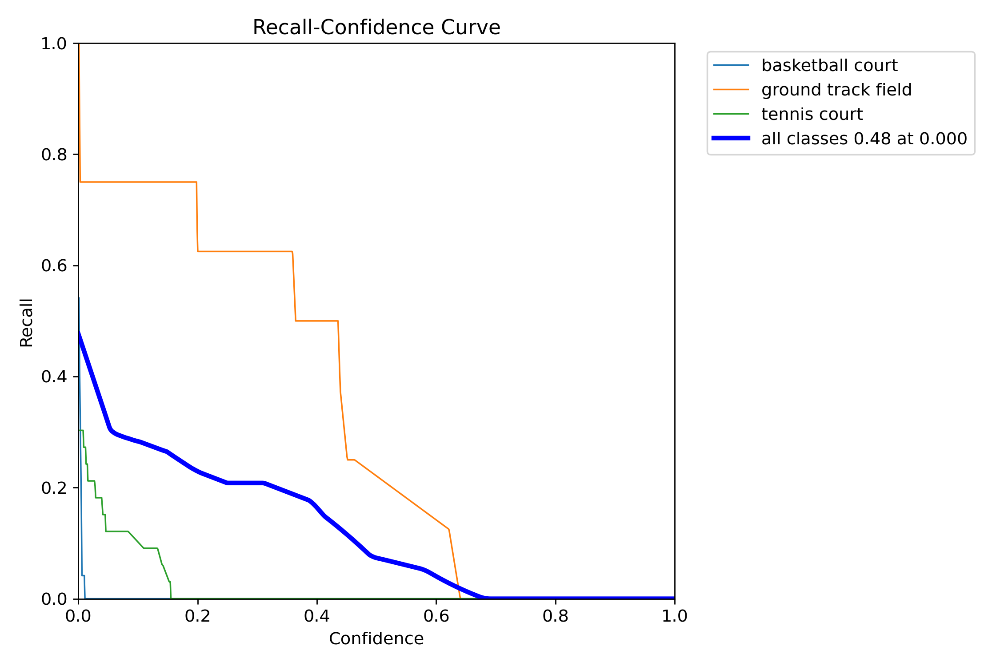
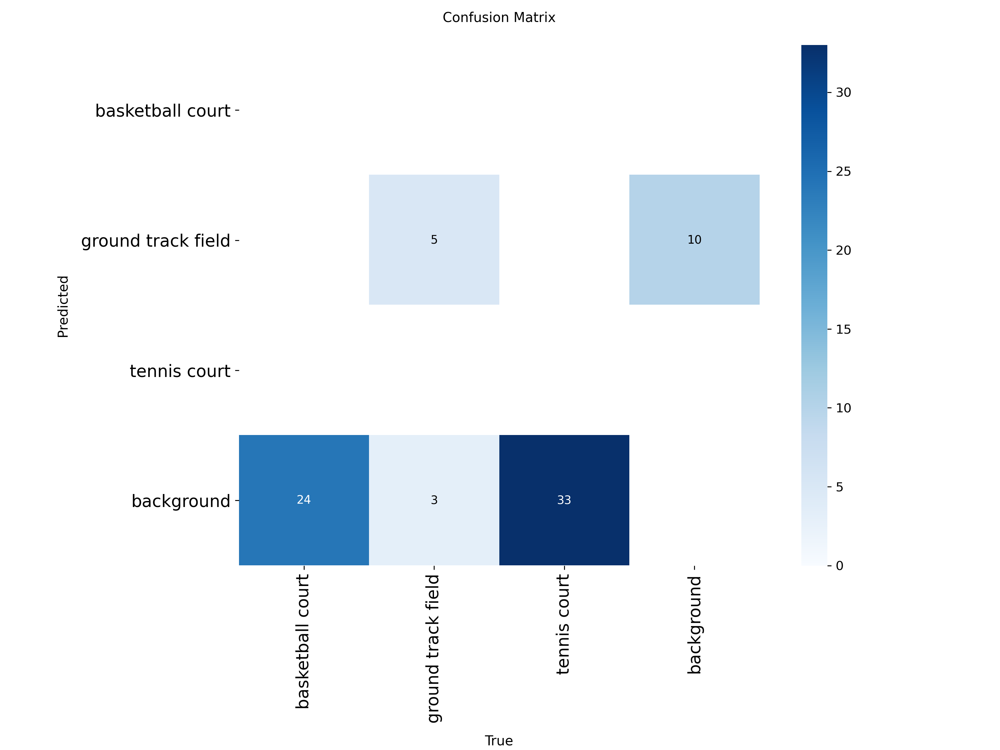
...
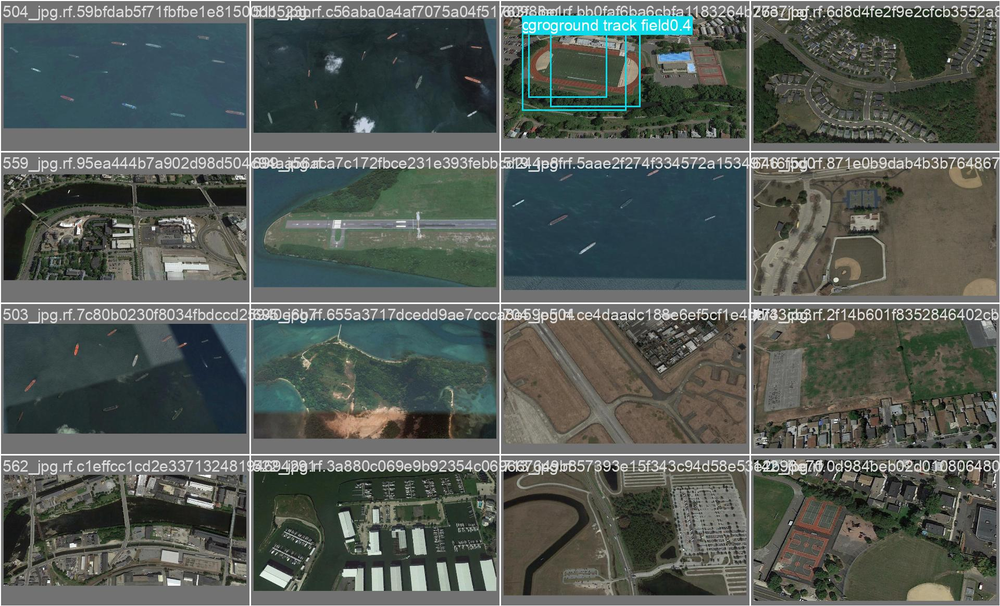
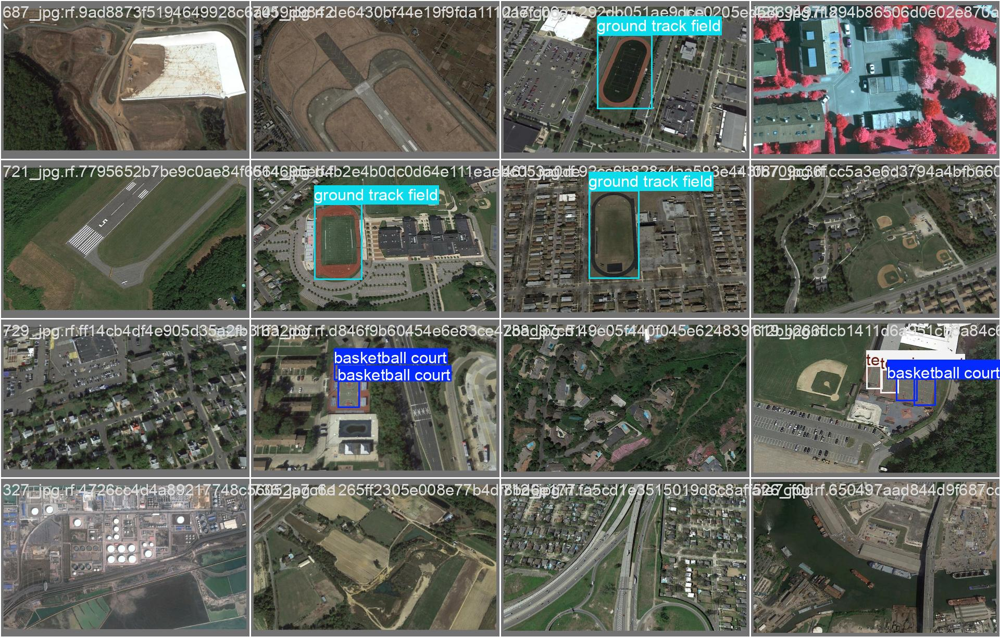
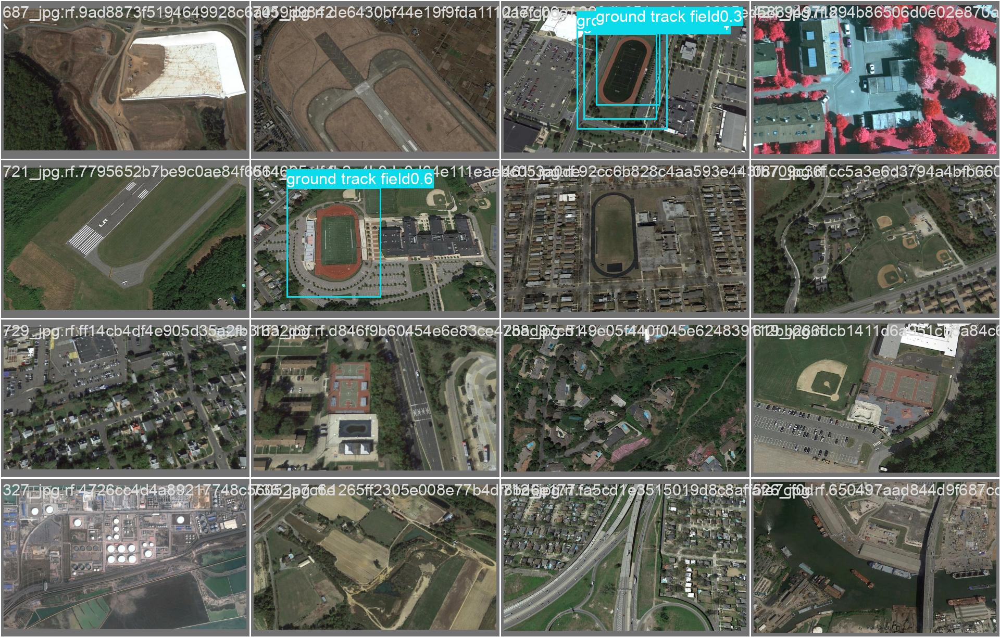
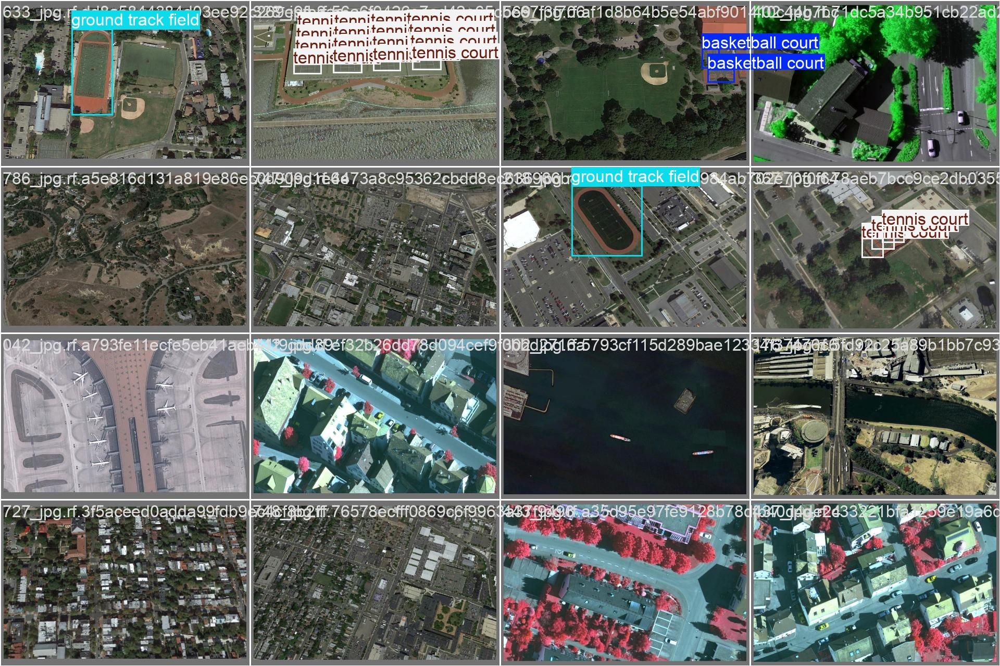
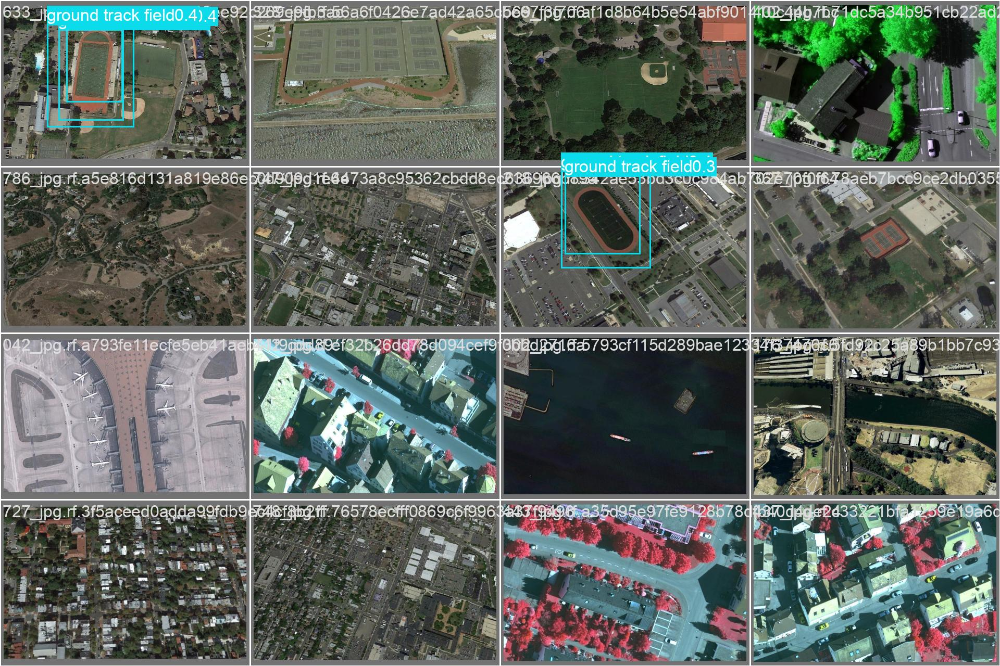

In [ ]:
display_mosaic('/content/runs/detect/val-2')


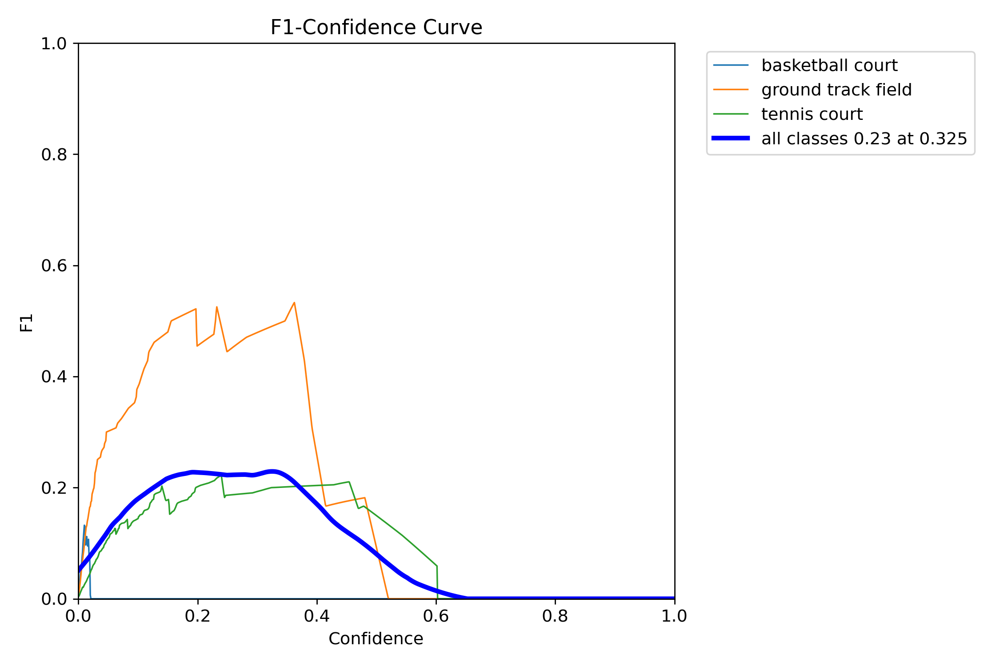
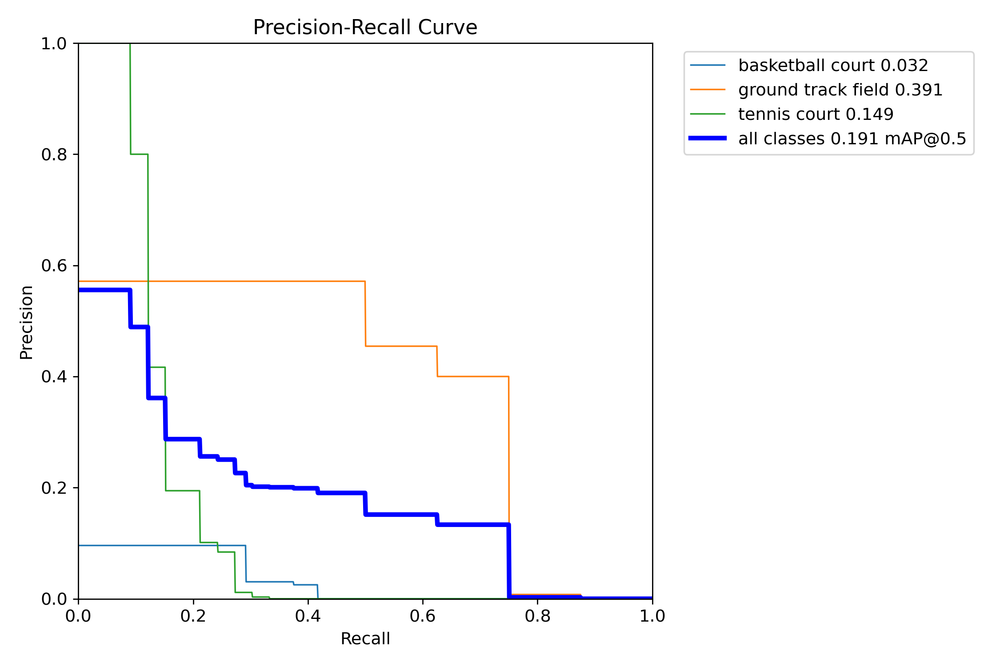
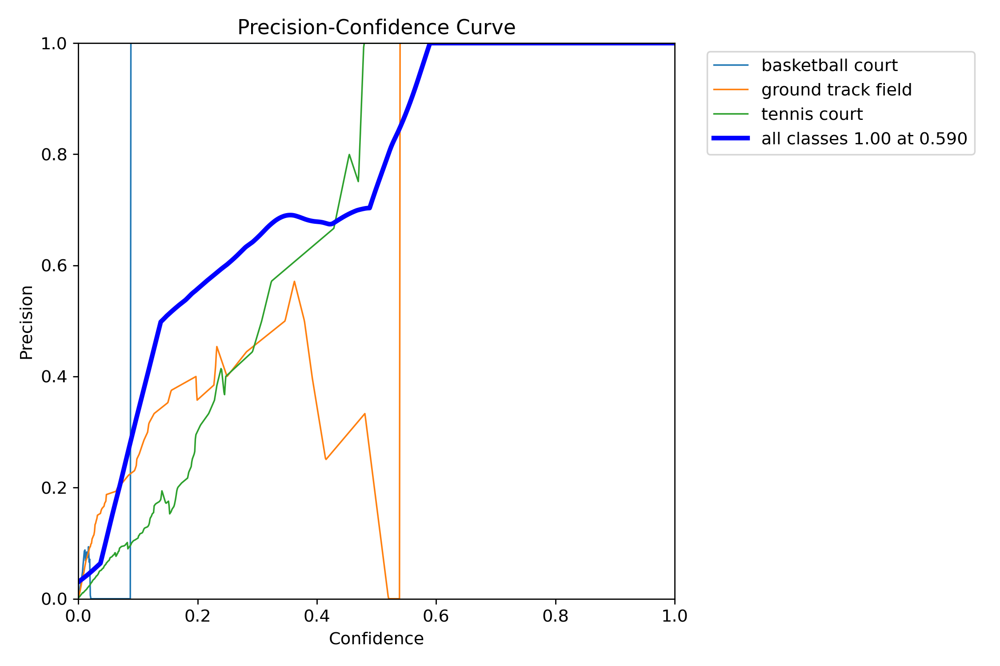
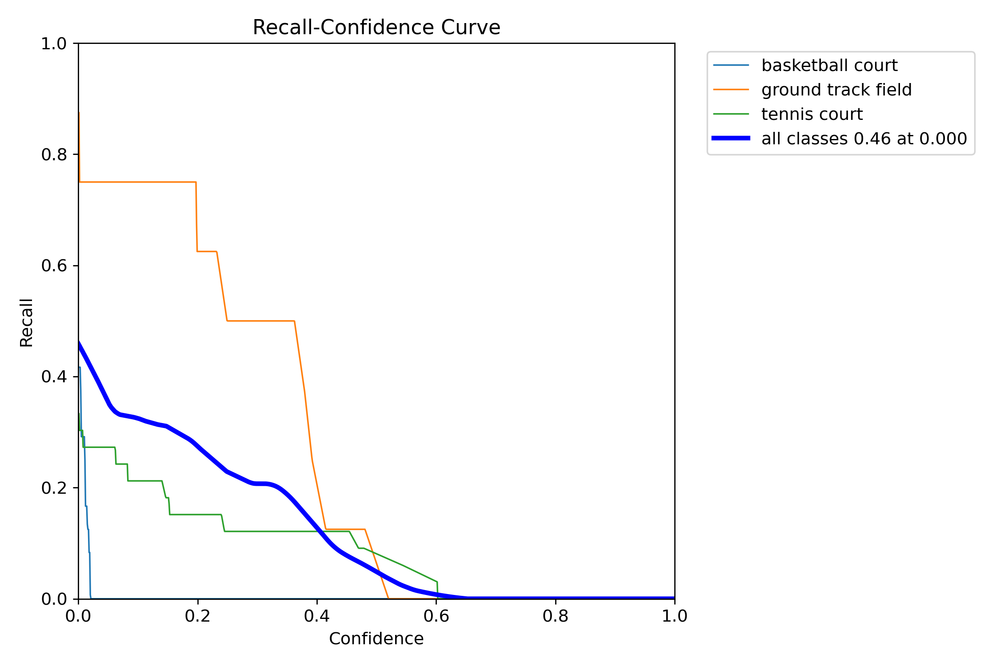
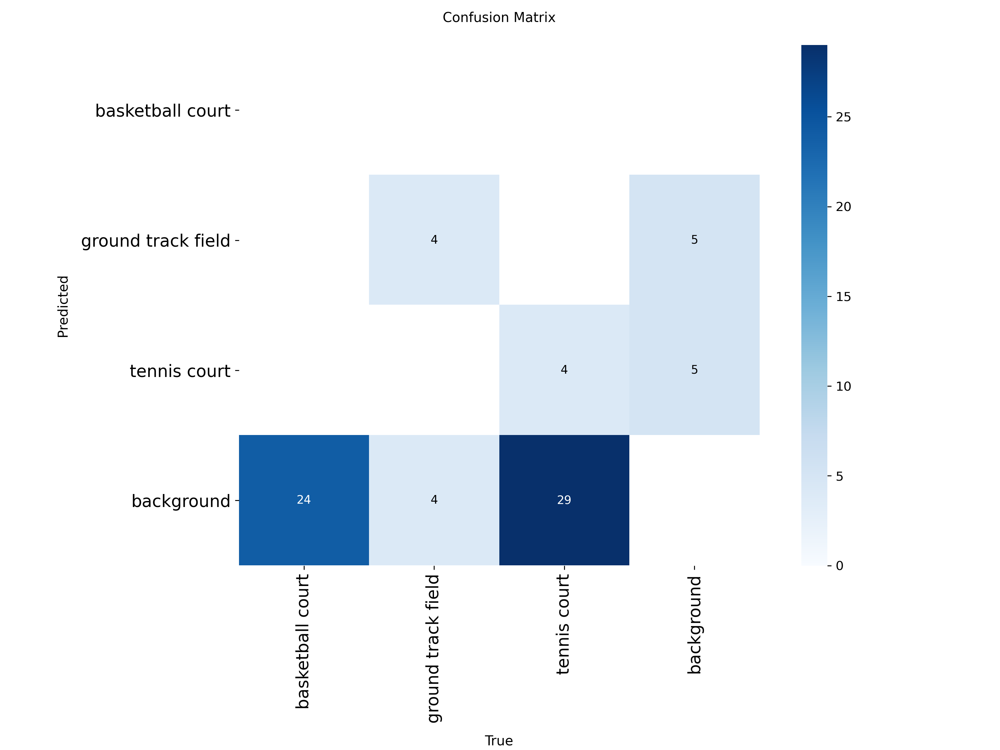
...
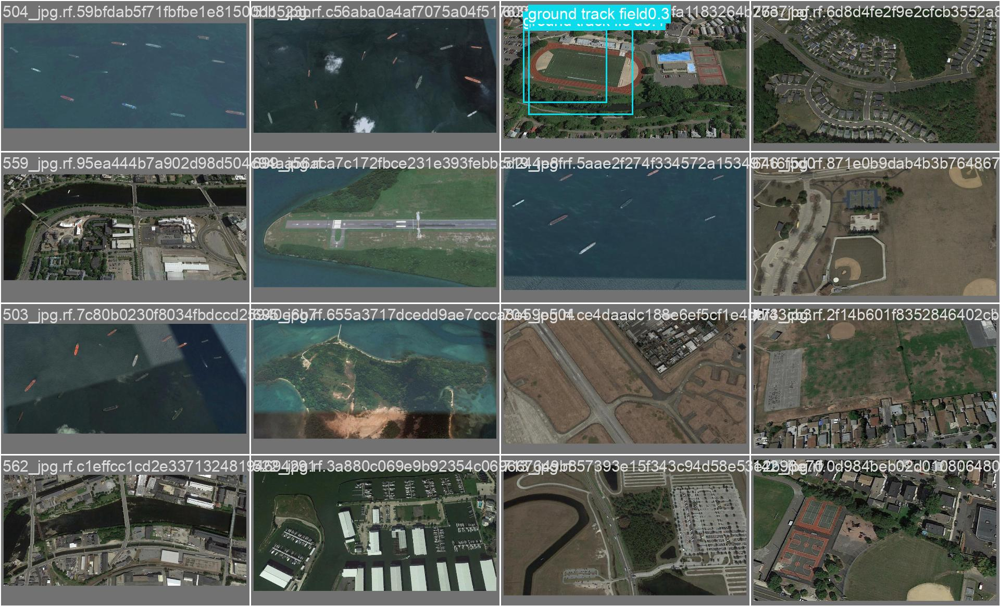
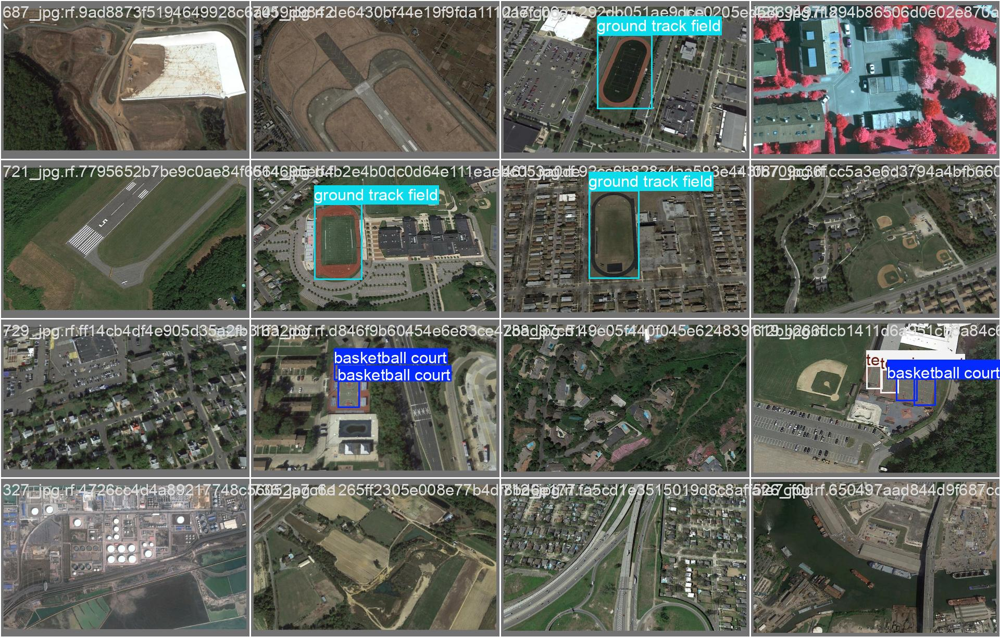
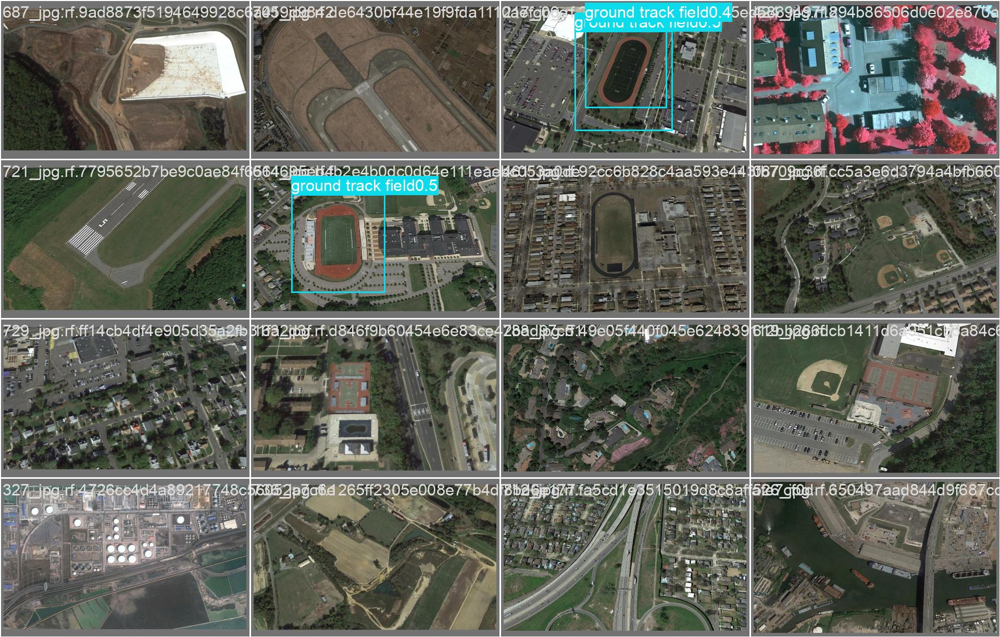
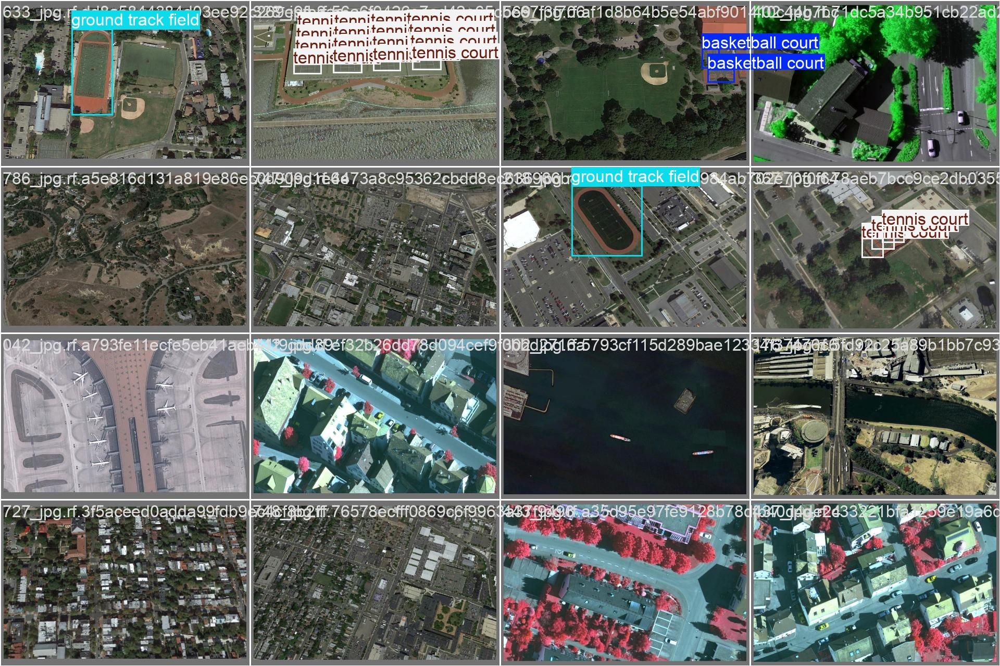
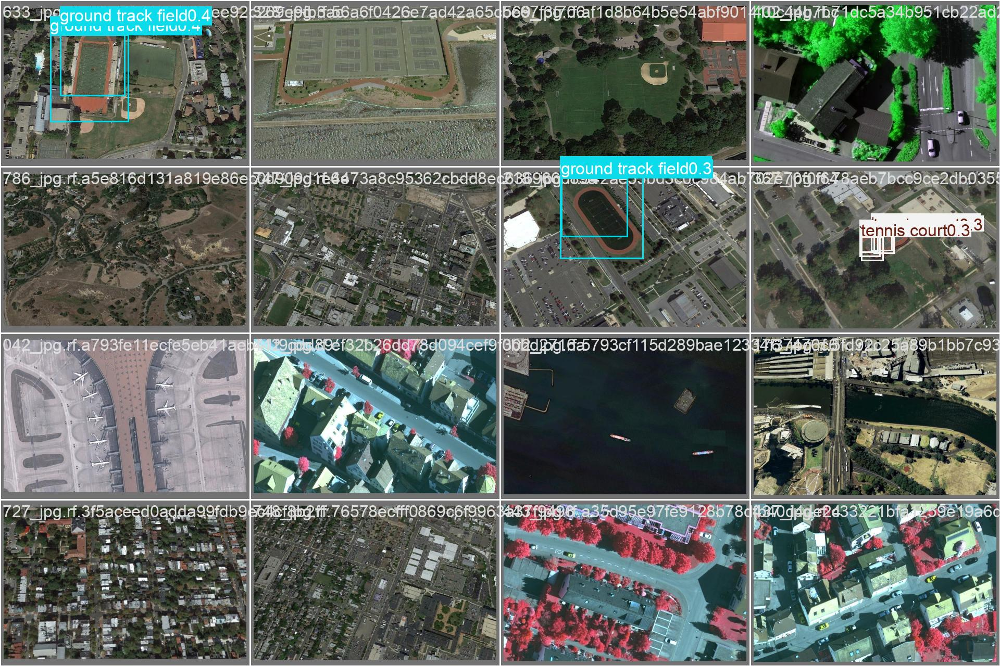

In [ ]:
display_mosaic('/content/runs/detect/val_modified')

In [ ]:
# @title 📊 YOLO-PICO Comparative Evaluation Dashboard {display-mode: "form"}
import os
import json
import pandas as pd
from google.colab import output
import IPython.display as display

def _report_js_error(message):
    print(f"Dashboard JS Error: {message}")

output.register_callback('report_js_error', _report_js_error)

# Best Epoch Training Validation Metrics
train_metrics = {
    "base": {"precision": 0.567, "recall": 0.294, "map50": 0.222, "map95": 0.0696},
    "mod": {"precision": 0.627, "recall": 0.327, "map50": 0.230, "map95": 0.0744}
}

# Test Split Validation Metrics
test_metrics = {
    "base": {"precision": 0.885, "recall": 0.208, "map50": 0.245, "map95": 0.0634},
    "mod": {"precision": 0.723, "recall": 0.248, "map50": 0.233, "map95": 0.0634}
}

html_content = """
<!DOCTYPE html>
<html>
<head>
  <meta charset="UTF-8">
  <title>YOLO-PICO Comparison Dashboard</title>
  <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
  <style>
    body {
      font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
      background-color: #f4f6f8;
      color: #333;
      margin: 0;
      padding: 20px;
    }
    .header {
      text-align: center;
      margin-bottom: 25px;
    }
    .header h1 {
      margin: 0;
      font-size: 26px;
      color: #2c3e50;
    }
    .header p {
      margin: 5px 0 0 0;
      color: #7f8c8d;
      font-size: 14px;
    }
    .table-container {
      background: #ffffff;
      border-radius: 8px;
      padding: 20px;
      margin-bottom: 25px;
      box-shadow: 0 2px 4px rgba(0,0,0,0.05);
    }
    .table-container h2 {
      margin: 0 0 15px 0;
      font-size: 18px;
      color: #2c3e50;
      border-left: 4px solid #3498db;
      padding-left: 10px;
    }
    table {
      width: 100%;
      border-collapse: collapse;
      margin-top: 10px;
    }
    th, td {
      padding: 12px 15px;
      text-align: center;
      border-bottom: 1px solid #e0e0e0;
    }
    th {
      background-color: #f8f9fa;
      color: #34495e;
      font-weight: 600;
      font-size: 13px;
      text-transform: uppercase;
    }
    tr:hover {
      background-color: #fdfdfd;
    }
    .badge {
      font-weight: 600;
      padding: 4px 8px;
      border-radius: 4px;
      font-size: 12px;
    }
    .badge.base {
      background-color: #ebf5fb;
      color: #2980b9;
    }
    .badge.mod {
      background-color: #eafaf1;
      color: #27ae60;
    }
    .highlight {
      font-weight: bold;
      color: #2c3e50;
    }
  </style>
</head>
<body>

  <div class="header">
    <h1>📊 YOLO-PICO Model Metrics Dashboard</h1>
    <p>Real-time performance metrics comparison between the Baseline (0.25 width) and Modified (0.35 width) architectures</p>
  </div>

  <div class="table-container">
    <h2>i) Training Performance Table (Best Validation Epoch)</h2>
    <table>
      <thead>
        <tr>
          <th>Model Config</th>
          <th>Box Precision (P)</th>
          <th>Recall (R)</th>
          <th>mAP50</th>
          <th>mAP50-95</th>
        </tr>
      </thead>
      <tbody>
        <tr>
          <td><span class="badge base">BASELINE</span></td>
          <td class="highlight">BASE_TR_P</td>
          <td>BASE_TR_R</td>
          <td>BASE_TR_MAP50</td>
          <td>BASE_TR_MAP95</td>
        </tr>
        <tr>
          <td><span class="badge mod">MODIFIED</span></td>
          <td class="highlight">MOD_TR_P</td>
          <td>MOD_TR_R</td>
          <td>MOD_TR_MAP50</td>
          <td>MOD_TR_MAP95</td>
        </tr>
      </tbody>
    </table>
  </div>

  <div class="table-container">
    <h2>ii) Testing Performance Table (Unseen Test Set)</h2>
    <table>
      <thead>
        <tr>
          <th>Model Config</th>
          <th>Box Precision (P)</th>
          <th>Recall (R)</th>
          <th>mAP50</th>
          <th>mAP50-95</th>
        </tr>
      </thead>
      <tbody>
        <tr>
          <td><span class="badge base">BASELINE</span></td>
          <td class="highlight">BASE_TS_P</td>
          <td>BASE_TS_R</td>
          <td>BASE_TS_MAP50</td>
          <td>BASE_TS_MAP95</td>
        </tr>
        <tr>
          <td><span class="badge mod">MODIFIED</span></td>
          <td class="highlight">MOD_TS_P</td>
          <td>MOD_TS_R</td>
          <td>MOD_TS_MAP50</td>
          <td>MOD_TS_MAP95</td>
        </tr>
      </tbody>
    </table>
  </div>

  <script>
    window.onerror = function(message) {
      google.colab.kernel.invokeFunction('report_js_error', [message], {});
    };
  </script>
</body>
</html>
"""

# Replace placeholders dynamically via pure python to avoid formatting conflicts
rendered = html_content.replace("BASE_TR_P", str(train_metrics["base"]["precision"]))
rendered = rendered.replace("BASE_TR_R", str(train_metrics["base"]["recall"]))
rendered = rendered.replace("BASE_TR_MAP50", str(train_metrics["base"]["map50"]))
rendered = rendered.replace("BASE_TR_MAP95", str(train_metrics["base"]["map95"]))

rendered = rendered.replace("MOD_TR_P", str(train_metrics["mod"]["precision"]))
rendered = rendered.replace("MOD_TR_R", str(train_metrics["mod"]["recall"]))
rendered = rendered.replace("MOD_TR_MAP50", str(train_metrics["mod"]["map50"]))
rendered = rendered.replace("MOD_TR_MAP95", str(train_metrics["mod"]["map95"]))

rendered = rendered.replace("BASE_TS_P", str(test_metrics["base"]["precision"]))
rendered = rendered.replace("BASE_TS_R", str(test_metrics["base"]["recall"]))
rendered = rendered.replace("BASE_TS_MAP50", str(test_metrics["base"]["map50"]))
rendered = rendered.replace("BASE_TS_MAP95", str(test_metrics["base"]["map95"]))

rendered = rendered.replace("MOD_TS_P", str(test_metrics["mod"]["precision"]))
rendered = rendered.replace("MOD_TS_R", str(test_metrics["mod"]["recall"]))
rendered = rendered.replace("MOD_TS_MAP50", str(test_metrics["mod"]["map50"]))
rendered = rendered.replace("MOD_TS_MAP95", str(test_metrics["mod"]["map95"]))

display.display(display.HTML(rendered))


Model Config,Box Precision (P),Recall (R),mAP50,mAP50-95
BASELINE,0.567,0.294,0.222,0.0696
MODIFIED,0.627,0.327,0.23,0.0744
Model Config,Box Precision (P),Recall (R),mAP50,mAP50-95
BASELINE,0.885,0.208,0.245,0.0634
MODIFIED,0.723,0.248,0.233,0.0634
